# 12C — Distributional NFL movement capacity (highest priority)

**Part 1 · Research question (Q3).** Can stable athlete-specific NFL speed-conditioned acceleration distributions be estimated more reliably than noisy maxima or fitted linear envelopes — and do Combine speed features predict them beyond official testing?

**Part 2 · Declared hypotheses (`m12.config.TRACKS`, fixed before execution).**
- *Primary H1 (measurement).* Upper conditional acceleration quantiles (τ = 0.90) averaged over the 12.0 shared speed range are more game-split reliable than the observed-maximum (C0a) and linear-envelope (C0b) estimates.
- *Primary H2 (transfer).* M3 (M1 + fitted sprint Vmax) lowers held-out RMSE of `nfl.q90_shared` vs M1; M2 (M1 + observed Combine top speed) lowers held-out RMSE of `nfl.game_top_speed_q75` vs M1. Holm over the two.
- *Secondary.* Held-out calibration / pinball / CRPS of the estimators; replication of the two 11B high-speed findings under declared variants (no variant chosen afterwards).

**Target freeze.** The estimator behind `nfl.q90_shared` is chosen by a declared reliability rule (`distributional_capacity.freeze_rule`) on NFL data ONLY and written to `m12c_target_freeze.json` before any Combine value is joined. The freeze is immutable.

**Not claimed.** An observed upper quantile is what the athlete did under game opportunity — not a physiological maximum; an unobserved envelope intercept is never a measured capacity. The histograms carry game and season but not down / alignment / role.

**Prerequisites.** 12.0 in the same `RUN_MODE`. **Run time.** No tracking scan; minutes (bootstrap matrix products, IRLS per athlete), plus the bounded permutation.

In [3]:
RUN_MODE = 'full'
SEED = 20261015
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
MEMORY_BUDGET_GB = 6.0
RUN_PERMUTATION = True       # athlete-label permutation of the primary transfer comparison (bounded: M12Config.n_perm)
RUN_REPLICATION = True       # C7 high-speed replication grid

In [4]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import ResearchStore
from nflbdb.research.advanced_movement.m11 import combine_drills as cd
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import speed_state as ss
from nflbdb.research.advanced_movement.m12 import advanced_evaluation as ae
from nflbdb.research.advanced_movement.m12 import config as m12c
from nflbdb.research.advanced_movement.m12 import distributional_capacity as dc
from nflbdb.research.advanced_movement.m12 import figures as fg
from nflbdb.research.advanced_movement.m12 import foundation as fd
from nflbdb.research.advanced_movement.m12 import functional_movement as fm
from nflbdb.research.advanced_movement.m12 import multiview_traits as mv
from nflbdb.research.advanced_movement.m12 import reporting as rp
from nflbdb.research.advanced_movement.m12 import synthesis as sy
from nflbdb.research.advanced_movement.m12 import validation as v12

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ResearchStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m12c.M12Config().for_mode(controls)
S = src.M11Sources(cfg, store, m11c.M11Config().for_mode(controls))
D = fd.M12Data(store, C, S)
PROV = m12c.provenance('12C', controls, C)
W = store.write_frame
MAN = fd.check_foundation(store, C)
BINS = MAN['shared_speed']['bins']
if not BINS:
    raise RuntimeError('12.0 found no shared speed range: 12C summary traits are undefined (see m12_shared_speed_support)')
SE_, AE_ = ae.speed_edges(C), ae.accel_edges(C)
SHARED = (MAN['shared_speed']['lo'], MAN['shared_speed']['hi'])
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · config `{C.hash()}` · shared speed range {SHARED[0]}–{SHARED[1]} yd/s ({len(BINS)} bins)'))

**Run mode: `full`** (FULL) · config `c2903a12f8449fa2` · shared speed range 1.0–7.0 yd/s (12 bins)

In [5]:
checks = v12.run_all((*v12.CHECKS_GENERAL, *v12.CHECKS_DISTRIBUTIONAL, *v12.CHECKS_FUNCTIONAL[:2]))
display(checks)
v12.assert_all_passed(checks)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:212: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(M, 0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:213: RuntimeWarning: Degrees of freedom <= 0 for slice.
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(S2, 0), 0.0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:213: RuntimeWarning: Mean of empty slice
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(S2, 0), 0.0)


check,status,detail
str,str,str
"""grouped_folds_and_leakage""","""PASS""","""athlete-grouped folds enforced…"
"""block_sees_training_only""","""PASS""","""fold-fitted blocks receive one…"
"""common_cohort_pairing""","""PASS""","""every model of a ladder is sco…"
"""bootstrap_unit_and_seed""","""PASS""","""athlete bootstrap deterministi…"
"""checkpoint_resume_safety""","""PASS""","""completion gate blocks partial…"
…,…,…
"""quantiles_and_crossing""","""PASS""","""vectorised histogram quantiles…"
"""game_splits_and_heldout""","""PASS""","""game splits partition games (o…"
"""pooling_and_trait""","""PASS""","""partial pooling shrinks toward…"


## Part 3 · Data and eligibility

NFL athletes with ≥ `min_games_athlete` games in the histograms (`elig_12C_nfl`); transfer analyses use the linked subset with a forty (`elig_12C_transfer`). One athlete = one cube of per-game histograms (games are the replication unit).

In [6]:
reg = D.m12('m12_cohort_registry')
gts = D.m12('m12_game_top_speed')
off, env, athf, nt = D.officials(), D.envelopes(), D.athlete_features(), D.nfl_targets()
ids = reg.filter(pl.col('elig_12C_nfl'))['nfl_id'].to_list()
POS = dict(zip(gts['nfl_id'].to_list(), gts['position_group'].to_list()))
POS |= {int(i): p for i, p in zip(reg['nfl_id'].to_list(), reg['position_group'].to_list()) if p is not None}
n_rows = int(D.hist().filter(pl.col('nfl_id').is_in(ids)).select(pl.len()).collect().item())
games_mean = float(reg.filter(pl.col('elig_12C_nfl'))['nfl_games'].mean() or 0)
display(ae.memory_plan([{'item': 'histogram rows of eligible athletes', 'n_rows': n_rows, 'n_cols': 6, 'bytes_per_value': 8},
                        {'item': 'athlete cubes (games × 23 × 64 int32)', 'n_rows': int(len(ids) * games_mean), 'n_cols': (SE_.size - 1) * (AE_.size - 1), 'bytes_per_value': 4},
                        {'item': 'bootstrap replicates per athlete (transient)', 'n_rows': C.env_boot, 'n_cols': (SE_.size - 1) * (AE_.size - 1), 'bytes_per_value': 8}], MEMORY_BUDGET_GB))
h = D.hist_athletes(ids)
cubes = dc.build_cubes(h, POS, C)
del h
print(f'{len(cubes)} NFL athletes with ≥ {C.min_games_athlete} games · {int(reg["elig_12C_transfer"].sum())} linked with a forty')

item,n_rows,n_cols,est_mb,on_disk_mb,note,budget_mb,within_budget
str,i64,i64,f64,null,str,f64,bool
"""histogram rows of eligible ath…",2962763,6,142.2,null,"""""",6000.0,true
"""athlete cubes (games × 23 × 64…",7592,1472,44.7,null,"""""",6000.0,true
"""bootstrap replicates per athle…",100,1472,1.2,null,"""""",6000.0,true


316 NFL athletes with ≥ 8 games · 267 linked with a forty


## Part 4 · Physical definitions

- **Q_τ(a | v)** — τ-quantile of tangential acceleration [yd/s²] among an athlete's eligible post-snap frames in a 0.5 yd/s speed bin; a bin is supported with ≥ `min_frames_bin_nfl` frames.
- **Estimators** C0a observed maximum · C0b linear envelope (Milestone 11 rule) · C1 empirical bin quantile · C2 smooth quantile P-spline · C3 position-pooled (empirical Bayes, game-bootstrap SE) · C4 non-increasing above `shape_vmin` (τ ≥ 0.9 only). C5 (distributional forest) is declared optional and NOT implemented (`dc.NOT_IMPLEMENTED`).
- **Summary trait** `nfl.q{τ}_shared` = mean of the curve over the shared speed bins, defined only when EVERY shared bin is supported (no composition bias from different speed coverage).
- **Speed target** `nfl.game_top_speed_q{50,75,90}` = quantile of the athlete's per-game maximum episode speed (09A episodes; games ≥ `min_games_athlete`).
- **C2 penalty λ** is tuned ONCE on a dedicated random game split (seed 999 — never an evaluation split), by held-out pinball loss; no Combine value is involved.

In [7]:
lam_tab = dc.tune_lambda(cubes, C, BINS, C.primary_tau)
LAM = float(lam_tab.filter(pl.col('pinball').is_finite()).sort('pinball', 'lambda')['lambda'][0]) if lam_tab['pinball'].is_finite().any() else float(C.spline_lambdas[1])
W(lam_tab, 'm12c_lambda_tuning')
display(lam_tab)
print(f'C2 penalty λ = {LAM}')
F_all = dc.curves(cubes, None, C.taus, C, LAM, C.env_boot, C.seed)
print('curves for every estimator × τ computed on all games')

lambda,tau,n_athletes,pinball
f64,f64,i64,f64
0.1,0.9,149,0.352119
1.0,0.9,149,0.352047
10.0,0.9,149,0.352029
100.0,0.9,149,0.352622


C2 penalty λ = 10.0


c:\Users\myben\.conda\envs\nfl\lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


curves for every estimator × τ computed on all games


## Part 5–6 · Baselines and advanced estimators — one athlete, all estimators

Rule-chosen athlete: the eligible athlete with the median number of frames in the shared range (no selection on values).

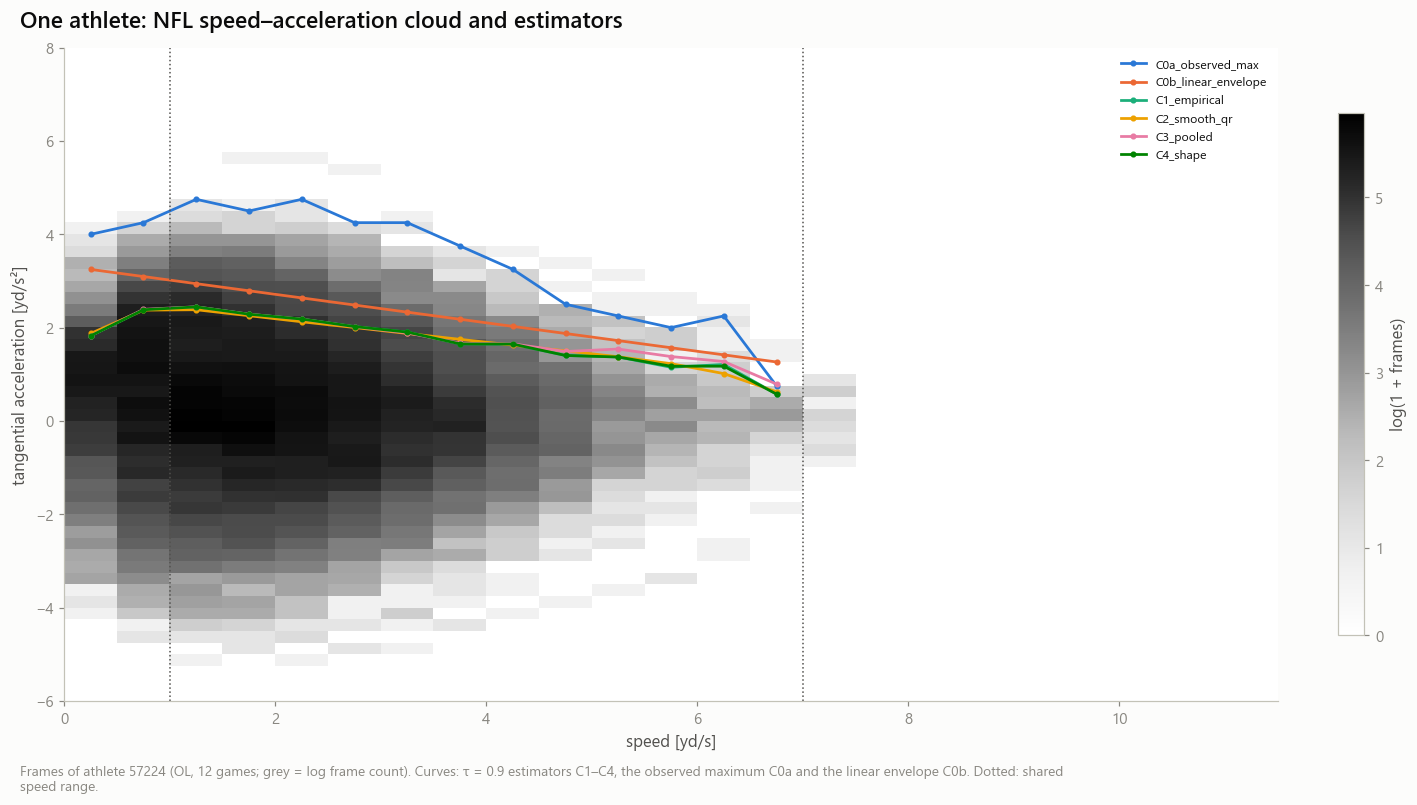

C:\Users\myben\AppData\Local\Temp\ipykernel_49892\1517636740.py:13: RuntimeWarning: Mean of empty slice
  pc += [{'position_group': p, 'tau': t, 'speed': float(ae.mids(SE_)[k]), 'accel_q': float(np.nanmean(M[:, k])), 'n_athletes': int(np.isfinite(M[:, k]).sum())} for k in range(M.shape[1])]


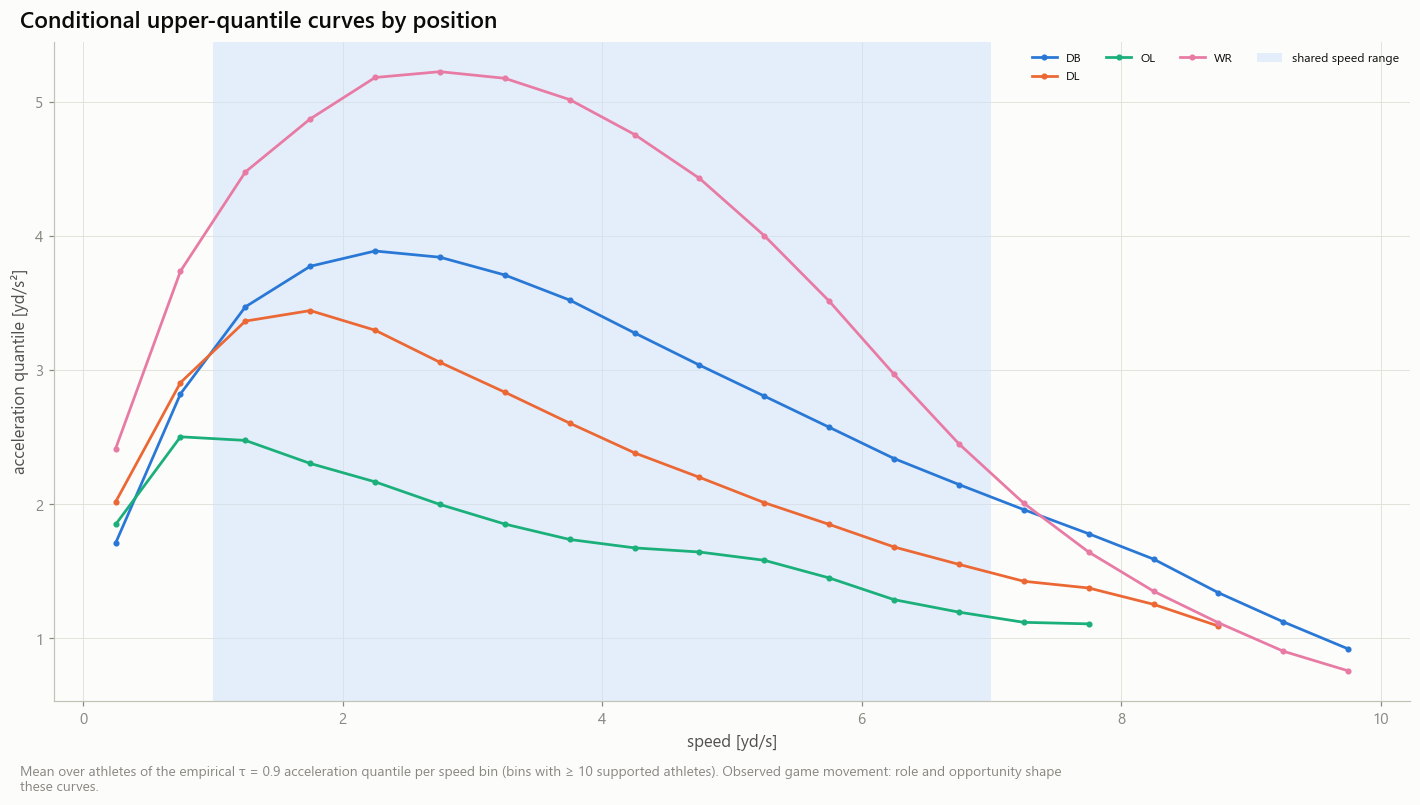

In [8]:
order = sorted(cubes, key=lambda i: (int(cubes[i].total()[BINS].sum()), i))
pick = order[len(order) // 2]
cv = {e: F_all[C.primary_tau][e][pick] for e in dc.ESTIMATORS}
store.show(fg.fig_athlete_cloud(cubes[pick].total(), SE_, AE_, cv, 'One athlete: NFL speed–acceleration cloud and estimators',
                                f'Frames of athlete {pick} ({cubes[pick].position}, {cubes[pick].games.size} games; grey = log frame count). Curves: τ = {C.primary_tau} estimators C1–C4, the observed maximum C0a and the linear envelope C0b. Dotted: shared speed range.', SHARED),
           'AM12_C_01_athlete_cloud', {}, publication=True, source='m11_envelope_hist', n='1 athlete (rule-chosen)')
pc = []
for t in C.taus:
    for p in sorted(set(c_.position for c_ in cubes.values())):
        M = np.array([F_all[t]['C1_empirical'][i] for i, cb in cubes.items() if cb.position == p])
        if M.shape[0] >= C.min_athletes:
            with np.errstate(invalid='ignore'):
                pc += [{'position_group': p, 'tau': t, 'speed': float(ae.mids(SE_)[k]), 'accel_q': float(np.nanmean(M[:, k])), 'n_athletes': int(np.isfinite(M[:, k]).sum())} for k in range(M.shape[1])]
pc = pl.DataFrame(pc)
W(pc, 'm12c_position_quantile_curves')
store.show(fg.fig_lines(pc.filter((pl.col('tau') == C.primary_tau) & (pl.col('n_athletes') >= 10)), 'speed', 'accel_q', 'position_group', 'Conditional upper-quantile curves by position',
                        f'Mean over athletes of the empirical τ = {C.primary_tau} acceleration quantile per speed bin (bins with ≥ 10 supported athletes). Observed game movement: role and opportunity shape these curves.',
                        'speed [yd/s]', 'acceleration quantile [yd/s²]', shade=SHARED), 'AM12_C_02_position_quantile_curves', {'curves': pc}, publication=True, source='m11_envelope_hist')

## Part 7a · Measurement reliability (game splits) — PRIMARY H1

Splits: odd / even game order (primary), `game_splits` seeded random halves, first season vs later seasons. Each half re-estimates every curve from its own games; the C3 position means and the bootstrap SEs come from that half only. Reported: trait split-half reliability (Spearman–Brown, athlete bootstrap), position-adjusted reliability, rank agreement, functional-shape agreement, per-bin reliability. **Primary H1 test:** reliability(C_x) − reliability(C0a / C0b) on the same athletes (odd / even split, τ = 0.90).

In [9]:
SPLITS = [('odd_even', 0)] + [('random', s) for s in range(1, C.game_splits + 1)] + [('season', 0)]
rel, binrel, splitvals = dc.reliability_tables(cubes, C, BINS, LAM, SPLITS, C.seed, progress=lambda s: print('reliability', s, flush=True))
spd_rel = dc.speed_reliability(gts, C, C.seed)
W(rel, 'm12c_reliability')
W(binrel, 'm12c_bin_reliability')
W(splitvals, 'm12c_split_traits')
W(spd_rel, 'm12c_speed_reliability')
rdiff = pl.DataFrame([dc.reliability_difference(splitvals, e, ref, C.primary_tau, 'odd_even:0', max(200, C.n_boot // 5), C.seed)
                      for e in dc.QUANTILE_ESTIMATORS for ref in ('C0a_observed_max', 'C0b_linear_envelope')], infer_schema_length=None)
rdiff = rdiff.with_columns(pl.struct('lo', 'hi').map_elements(lambda s: ae.reading(s['lo'] if s['lo'] is not None else np.nan, s['hi'] if s['hi'] is not None else np.nan), return_dtype=pl.String).alias('verdict'))
W(rdiff, 'm12c_reliability_difference')
with pl.Config(tbl_rows=-1, tbl_width_chars=240):
    display(rel.filter(pl.col('split') == 'odd_even:0').select('tau', 'estimator', 'n_athletes', 'reliability', 'rel_lo', 'rel_hi', 'rho_half', 'reliability_pos_adj', 'shape_agreement').sort('tau', 'estimator'))
    display(rdiff)
    display(spd_rel)

c:\Users\myben\.conda\envs\nfl\lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:212: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(M, 0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:213: RuntimeWarning: Degrees of freedom <= 0 for slice.
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(S2, 0), 0.0)
C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\distributional_capacity.py:213: RuntimeWarning: Mean of empty slice
  tau2 = np.maximum(np.nanvar(M, 0) - np.nanmean(S2, 0), 0.0)


reliability odd_even:0 τ=0.5
reliability odd_even:0 τ=0.75
reliability odd_even:0 τ=0.9
reliability odd_even:0 τ=0.95
reliability random:1 τ=0.5
reliability random:1 τ=0.75
reliability random:1 τ=0.9
reliability random:1 τ=0.95
reliability random:2 τ=0.5
reliability random:2 τ=0.75
reliability random:2 τ=0.9
reliability random:2 τ=0.95
reliability random:3 τ=0.5
reliability random:3 τ=0.75
reliability random:3 τ=0.9
reliability random:3 τ=0.95
reliability season:0 τ=0.5
reliability season:0 τ=0.75
reliability season:0 τ=0.9
reliability season:0 τ=0.95


tau,estimator,n_athletes,reliability,rel_lo,rel_hi,rho_half,reliability_pos_adj,shape_agreement
f64,str,i64,f64,f64,f64,f64,f64,f64
0.5,"""C0a_observed_max""",241,0.9588,0.941763,0.972446,0.927539,0.893278,0.953587
0.5,"""C0b_linear_envelope""",241,0.994883,0.993233,0.996267,0.971669,0.956405,1.0
0.5,"""C1_empirical""",241,0.925493,0.887966,0.953461,0.885201,0.86625,0.808957
0.5,"""C2_smooth_qr""",241,0.921334,0.886023,0.949679,0.881205,0.863813,0.956714
0.5,"""C3_pooled""",241,0.968609,0.954355,0.980766,0.957528,0.901047,0.906651
0.5,"""C4_shape""",241,0.925493,0.887966,0.953461,0.885201,0.86625,0.808957
0.75,"""C0a_observed_max""",241,0.9588,0.941763,0.972446,0.927539,0.893278,0.953587
0.75,"""C0b_linear_envelope""",241,0.994883,0.993233,0.996267,0.971669,0.956405,1.0
0.75,"""C1_empirical""",241,0.988639,0.983295,0.991944,0.977653,0.907622,0.925727


estimator,reference,tau,split,n_athletes,rel_a,rel_b,diff,lo,hi,verdict
str,str,f64,str,i64,f64,f64,f64,f64,f64,str
"""C1_empirical""","""C0a_observed_max""",0.9,"""odd_even:0""",241,0.995803,0.9588,0.037003,0.022807,0.05432,"""supported"""
"""C1_empirical""","""C0b_linear_envelope""",0.9,"""odd_even:0""",241,0.995803,0.994883,0.00092,-0.000176,0.001976,"""inconclusive"""
"""C2_smooth_qr""","""C0a_observed_max""",0.9,"""odd_even:0""",241,0.995739,0.9588,0.03694,0.022636,0.054273,"""supported"""
"""C2_smooth_qr""","""C0b_linear_envelope""",0.9,"""odd_even:0""",241,0.995739,0.994883,0.000856,-0.000257,0.001873,"""inconclusive"""
"""C3_pooled""","""C0a_observed_max""",0.9,"""odd_even:0""",241,0.997585,0.9588,0.038786,0.02508,0.056197,"""supported"""
"""C3_pooled""","""C0b_linear_envelope""",0.9,"""odd_even:0""",241,0.997585,0.994883,0.002702,0.001568,0.003982,"""supported"""
"""C4_shape""","""C0a_observed_max""",0.9,"""odd_even:0""",241,0.995842,0.9588,0.037042,0.022841,0.054355,"""supported"""
"""C4_shape""","""C0b_linear_envelope""",0.9,"""odd_even:0""",241,0.995842,0.994883,0.000958,-0.000116,0.002021,"""inconclusive"""


target,q,n_athletes,r_half,rho_half,reliability,rel_lo,rel_hi
str,f64,i64,f64,f64,f64,f64,f64
"""nfl.game_top_speed_q50""",0.5,314,0.938111,0.932346,0.968068,0.958343,0.975639
"""nfl.game_top_speed_q75""",0.75,314,0.932454,0.923319,0.965046,0.955733,0.972826
"""nfl.game_top_speed_q90""",0.9,314,0.928036,0.924182,0.962675,0.955097,0.970364


## Part 7b · Held-out distributional forecasts (train games → test games)

Each estimator is fitted on the odd games and scored on the even games' frames: pinball loss per τ (athlete-averaged over supported shared bins; athletes weigh equally), coverage (share of held-out frames ≤ estimate; calibrated = τ), CRPS by quantile decomposition on a fixed τ grid (C1–C3), and the quantile-crossing rate of the raw curves.

In [10]:
ft = dc.forecast_table(cubes, C, BINS, LAM)
fs = dc.forecast_summary(ft, C, C.seed)
W(ft, 'm12c_forecast_athletes')
W(fs, 'm12c_forecast_summary')
with pl.Config(tbl_rows=-1, tbl_width_chars=240):
    display(fs.sort('tau', 'estimator'))

estimator,tau,n_athletes,pinball,coverage,coverage_gap,gain_vs_ref,gain_lo,gain_hi,crps,crossing_rate
str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""C0a_observed_max""",0.5,315,NaN,NaN,NaN,-1.524913,-1.558511,-1.490613,null,null
"""C0b_linear_envelope""",0.5,314,NaN,NaN,NaN,-0.804198,-0.82327,-0.78489,null,null
"""C1_empirical""",0.5,315,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN
"""C2_smooth_qr""",0.5,315,NaN,NaN,NaN,0.001364,0.001073,0.001691,NaN,NaN
"""C3_pooled""",0.5,315,NaN,NaN,NaN,0.001038,0.000606,0.001448,NaN,NaN
"""C4_shape""",0.5,315,NaN,NaN,NaN,0.0,0.0,0.0,null,null
"""C0a_observed_max""",0.75,315,NaN,NaN,NaN,-0.520675,-0.537452,-0.504173,null,null
"""C0b_linear_envelope""",0.75,314,NaN,NaN,NaN,-0.17571,-0.180233,-0.171629,null,null
"""C1_empirical""",0.75,315,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN


## Part 7c · Target freeze (declared rule, NFL data only — before any Combine value is joined)

In [11]:
decision = dc.freeze_rule(rel, C)
FREEZE = dc.write_freeze(store, decision, BINS, LAM, C)
display(Markdown(f"**Frozen primary target** `nfl.q90_shared` = estimator **{FREEZE['estimator']}** at τ = {FREEZE['tau']} over {len(FREEZE['shared_bins'])} shared bins "
                 f"(freeze `{FREEZE['freeze_hash']}`, {FREEZE['frozen_at']}){' — FLAG: ' + FREEZE['decision']['flag'] if FREEZE['decision'].get('flag') else ''}"))
tg = dc.athlete_targets(cubes, gts, env, FREEZE, C, C.seed)
W(tg, 'm12c_targets')
display(tg.select([c for c in tg.columns if c.startswith(('nfl.', 'env.'))]).describe())

**Frozen primary target** `nfl.q90_shared` = estimator **C3_pooled** at τ = 0.9 over 12 shared bins (freeze `bd09ec1a4faa369f`, 2026-10-15T00:40:50Z)

statistic,nfl.q50_shared,nfl.q75_shared,nfl.q90_shared,nfl.q95_shared,nfl.game_top_speed_q50,nfl.game_top_speed_q75,nfl.game_top_speed_q90,env.lin_V0,env.lin_A0,env.lin_V0_se,env.lin_V0_q90,env.lin_V0_q99,env.upper_tail_accel
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",316.0,316.0,316.0,316.0,314.0,314.0,314.0,316.0,316.0,316.0,316.0,316.0,316.0
"""null_count""",0.0,0.0,0.0,0.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",NaN,NaN,NaN,NaN,7.61654,8.115204,8.511921,NaN,5.196361,7.835352,NaN,13.422118,4.421723
"""std""",NaN,NaN,NaN,NaN,1.370465,1.275582,1.216254,NaN,1.344985,114.31294,NaN,3.079183,0.995466
"""min""",-0.260452,0.828844,1.605955,2.054755,4.295599,5.526103,5.856565,7.554455,2.456901,0.067672,6.940087,9.532465,2.451471
"""25%""",0.08282,1.391248,2.39048,2.861751,6.385148,6.87969,7.390611,10.923456,3.995819,0.245072,10.360417,11.884355,3.478728
"""50%""",0.183466,1.966521,3.196052,3.815854,7.761915,8.296458,8.688285,12.020307,5.360844,0.428792,11.394611,12.724074,4.598864
"""75%""",0.339887,2.74134,4.169359,4.587629,8.871316,9.300665,9.633448,13.509285,6.211905,0.746678,12.98745,14.158381,5.064583
"""max""",0.59903,3.623085,4.911362,5.389188,9.800342,10.043786,10.800787,61.386207,8.238619,2030.324415,91.091511,43.542294,6.813462


## Part 7d · Combine → NFL transfer ladder (PRIMARY H2)

M0 position + draft year · M1 + height, weight, official forty, 10-yd split · M2 M1 + observed Combine top speed · M3 M1 + fitted sprint Vmax · M4 M1 + phase-plane V0 · M5 M1 + fold-fitted FPCA scores of the Combine a(v) curve · M6 M1 + the 12D selected multi-view representation (only when 12D has executed; otherwise reported as `not_run` here and evaluated in 12G). **Identical athletes** for every model of a target (all static predictors non-null). Athlete folds from 12.0. Primary comparisons Holm-adjusted; the rest Benjamini–Hochberg (exploratory).

In [12]:
cw = cd.wide(athf, ['forty.v_max_obs', 'forty.sprint_vmax', 'forty.phase_V0'])
nw = ss.nfl_wide(nt).select('nfl_id', *[c for c in ('nfl.vmax_p90',) if c in ss.nfl_wide(nt).columns])
fman = D.m12('m12_fold_manifest').select('nfl_id', 'fold')
link_ids = reg.filter(pl.col('elig_12C_transfer'))['nfl_id'].to_list()
data = (off.filter(pl.col('nfl_id').is_in(link_ids)).join(cw, on='nfl_id', how='left').join(tg.drop('position_group'), on='nfl_id', how='inner')
        .join(nw, on='nfl_id', how='left').join(fman, on='nfl_id', how='inner').sort('nfl_id'))
curves = D.m12('m12_combine_curves')
ids_c, Mc, bridged = fm.combine_athlete_matrix(curves, BINS, C)
m5 = lambda a_ids: fm.fpca_block(a_ids, ids_c, Mc, C)
m6 = None
if (store.data_dir / 'm12d_selected_representation.json').is_file():
    sel = store.read_json('m12d_selected_representation', fd.NB['12D'])
    views = mv.view_features(athf['feature'].unique().to_list())
    mv_ids, mv_X, mv_feats, mv_views = mv.athlete_matrix(athf, views)
    m6 = lambda a_ids: mv.factor_block(sel['model'], sel['k'], mv_ids, mv_X, mv_views, POS, a_ids, C, C.seed)
MODELS = dc.ladder(m5, m6)
TARGETS = ['nfl.q90_shared', 'nfl.game_top_speed_q75', 'nfl.q95_shared', 'nfl.q50_shared', 'env.lin_V0', 'nfl.vmax_p90']
tr_rows, tr_oof = dc.transfer(data, TARGETS, MODELS, C, C.seed)
W(tr_rows, 'm12c_transfer')
W(tr_oof, 'm12c_transfer_oof')
with pl.Config(tbl_rows=-1, tbl_width_chars=260):
    display(tr_rows.select('target', 'model', 'reference', 'primary', 'n_athletes', 'delta_rmse', 'delta_lo', 'delta_hi', 'delta_pct', 'p_holm_primary', 'p_bh_exploratory', 'verdict'))
print('M6 multi-view:', 'included' if m6 is not None else 'not_run (12D not executed yet; evaluated in 12G)')

target,model,reference,primary,n_athletes,delta_rmse,delta_lo,delta_hi,delta_pct,p_holm_primary,p_bh_exploratory,verdict
str,str,str,bool,i64,f64,f64,f64,f64,f64,f64,str
"""nfl.q90_shared""","""M1""","""M0""",false,246,0.050016,0.03724,0.064547,22.815884,null,0.0,"""model_better"""
"""nfl.q90_shared""","""M2""","""M1""",false,246,-0.000669,-0.003066,0.00161,-0.395505,null,1.0,"""inconclusive"""
"""nfl.q90_shared""","""M3""","""M1""",true,246,-0.000839,-0.001834,0.000189,-0.495921,0.949,null,"""inconclusive"""
"""nfl.q90_shared""","""M4""","""M1""",false,246,-0.001339,-0.004109,0.000264,-0.791557,null,1.0,"""inconclusive"""
"""nfl.q90_shared""","""M5""","""M1""",false,246,-0.000327,-0.002167,0.001365,-0.193247,null,1.0,"""inconclusive"""
"""nfl.game_top_speed_q75""","""M1""","""M0""",false,266,0.069807,0.041219,0.099587,14.15259,null,0.0,"""model_better"""
"""nfl.game_top_speed_q75""","""M2""","""M1""",true,266,0.004963,-0.001034,0.010701,1.171985,0.098,null,"""inconclusive"""
"""nfl.game_top_speed_q75""","""M3""","""M1""",false,266,-0.003771,-0.008204,0.000192,-0.890638,null,1.0,"""inconclusive"""
"""nfl.game_top_speed_q75""","""M4""","""M1""",false,266,0.000215,-0.003291,0.003884,0.050796,null,1.0,"""inconclusive"""


M6 multi-view: not_run (12D not executed yet; evaluated in 12G)


In [13]:
# negative control and position subgroups of the primary transfer comparison
static = [k for k in ('forty.v_max_obs', 'forty.sprint_vmax', 'forty.phase_V0')]
dp = data.filter(pl.all_horizontal([pl.col(k).is_not_null() for k in static]) & pl.col('nfl.q90_shared').is_not_null())
perm = ae.permutation_blocks(dp, 'nfl.q90_shared', MODELS['M1'], MODELS['M3'], C, C.seed) if RUN_PERMUTATION and dp.height >= C.min_athletes else {}
res_p = ae.oof_ladder(dp, 'nfl.q90_shared', {'M1': MODELS['M1'], 'M3': MODELS['M3'], 'M5': MODELS['M5']}, C, C.seed)
bypos = pl.concat([ae.compare_by_position(res_p, m, 'M1', C, C.seed, target='nfl.q90_shared') for m in ('M3', 'M5')], how='diagonal_relaxed')
plus = ae.oof_ladder(dp, 'nfl.q90_shared', {'M1+': ae.Model(list(ae.M1_PLUS)), 'M3+': ae.Model([*ae.M1_PLUS, 'forty.sprint_vmax'])}, C, C.seed)
sens_plus = ae.compare(plus, [('M3+', 'M1+')], C, C.seed, target='nfl.q90_shared', note='M1 with official agility times')
W(pl.DataFrame([perm]) if perm else pl.DataFrame(), 'm12c_permutation')
W(bypos, 'm12c_transfer_by_position')
W(sens_plus, 'm12c_transfer_m1plus')
display(pl.DataFrame([perm]) if perm else Markdown('_permutation not run_'))
display(bypos.select('target', 'position_group', 'model', 'n_athletes', 'delta_rmse', 'delta_lo', 'delta_hi', 'verdict') if bypos.height else bypos)
display(sens_plus)

observed,n_perm,null_mean,null_q95,p_value
f64,i64,f64,f64,f64
-0.000839,200,-0.000491,0.000835,0.736318


target,position_group,model,n_athletes,delta_rmse,delta_lo,delta_hi,verdict
str,str,str,i64,f64,f64,f64,str
"""nfl.q90_shared""","""DB""","""M3""",60,0.0005,-0.000888,0.001706,"""inconclusive"""
"""nfl.q90_shared""","""DL""","""M3""",60,-0.000719,-0.001703,0.000491,"""inconclusive"""
"""nfl.q90_shared""","""OL""","""M3""",38,-0.000768,-0.007038,0.004281,"""inconclusive"""
"""nfl.q90_shared""","""TE""","""M3""",24,-0.002159,-0.005708,0.000662,"""inconclusive"""
"""nfl.q90_shared""","""WR""","""M3""",64,-0.001313,-0.002936,0.000182,"""inconclusive"""
"""nfl.q90_shared""","""DB""","""M5""",60,-0.000151,-0.005337,0.003799,"""inconclusive"""
"""nfl.q90_shared""","""DL""","""M5""",60,0.000325,-0.002907,0.004481,"""inconclusive"""
"""nfl.q90_shared""","""OL""","""M5""",38,-0.000692,-0.003103,0.00261,"""inconclusive"""
"""nfl.q90_shared""","""TE""","""M5""",24,-0.002025,-0.005568,0.001079,"""inconclusive"""


target,note,model,reference,n_athletes,rmse_ref,rmse_model,delta_rmse,delta_lo,delta_hi,delta_pct,spearman_ref,spearman_model,r2_ref,r2_model,p_boot_le0,verdict
str,str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""nfl.q90_shared""","""M1 with official agility times""","""M3+""","""M1+""",246,0.172632,0.173456,-0.000824,-0.00181,0.000196,-0.4774,0.960052,0.959953,0.963102,0.962749,0.934,"""inconclusive"""


## Part 7e · C7 — replication of the two 11B high-speed findings

Pairs: `forty.sprint_vmax → env.lin_V0` and `forty.v_max_obs → nfl.vmax_p90` (the 11B intervals excluded 0 — candidate discoveries). Declared variants, ALL reported, none selected afterwards: as in 11B (fixed M1) · alternative upper-quantile estimators (q90 / q95 shared, envelope V0 at q90 / q99, game top-speed q50 / q75 / q90) · first NFL season only · later seasons only · exposure ≥ 16 and ≥ 24 games. Plus the game-split reliability of the two 11B targets and position subgroups.

In [14]:
rep_tab, rep_sum, rep_rel, rep_pos = pl.DataFrame(), pl.DataFrame(), pl.DataFrame(), pl.DataFrame()
if RUN_REPLICATION:
    ep = D.episodes()
    first = ep.group_by('nfl_id').agg(pl.col('season').min().alias('_f'))

    def subset_cubes(which):
        out = {}
        for i, cb in cubes.items():
            m = cb.seasons == cb.seasons.min() if which == 'first' else cb.seasons > cb.seasons.min()
            if m.sum() >= max(2, C.min_games_athlete // 2):
                out[i] = dc.Cube(i, cb.position, cb.games[m], cb.seasons[m], cb.H[m])
        return out

    def season_targets(cs, cond):
        t = pl.DataFrame([{'nfl_id': i, 'env.lin_V0': dc.linear_envelope_curve(cb.total(), C)[1]['V0']} for i, cb in cs.items()], schema={'nfl_id': pl.Int64, 'env.lin_V0': pl.Float64})
        e2 = ep.join(first, on='nfl_id').filter(cond)
        v = (e2.filter(pl.col('demand_id') == 'sustained_high').group_by('nfl_id').agg(pl.col('v_max').quantile(0.9, 'linear').alias('nfl.vmax_p90'), pl.len().alias('_n'))
             .filter(pl.col('_n') >= 10).drop('_n'))
        return t.join(v, on='nfl_id', how='left')

    base = data
    extra = {}
    for nm, which, cond in (('first_season_only', 'first', pl.col('season') == pl.col('_f')), ('later_seasons_only', 'later', pl.col('season') > pl.col('_f'))):
        extra[nm] = base.drop('env.lin_V0', 'nfl.vmax_p90', strict=False).join(season_targets(subset_cubes(which), cond), on='nfl_id', how='inner')
    for k in (16, 24):
        extra[f'min_games_{k}'] = base.filter(pl.col('n_games') >= k)
    rep_tab = dc.replication_table(dc.replication_variants(base, extra), C, C.seed)
    rep_sum = dc.replication_summary(rep_tab)
    # game-split reliability of the two 11B targets
    va, vb = [], []
    for i, cb in cubes.items():
        a_, b_ = dc.game_splits(cb, 'odd_even')
        va.append(dc.linear_envelope_curve(cb.total(a_), C)[1]['V0'])
        vb.append(dc.linear_envelope_curve(cb.total(b_), C)[1]['V0'])
    r1 = ae.split_reliability(np.array(va), np.array(vb), max(200, C.n_boot // 5), C.seed)
    eh = (ep.filter(pl.col('demand_id') == 'sustained_high').with_columns((pl.col('game_id').rank('dense').over('nfl_id') % 2).alias('_h'))
          .group_by('nfl_id', '_h').agg(pl.col('v_max').quantile(0.9, 'linear').alias('_v'), pl.len().alias('_n')).filter(pl.col('_n') >= 5)
          .pivot(on='_h', index='nfl_id', values='_v').drop_nulls())
    r2 = ae.split_reliability(eh[eh.columns[1]].to_numpy(), eh[eh.columns[2]].to_numpy(), max(200, C.n_boot // 5), C.seed) if eh.width == 3 else {'n_athletes': 0}
    rep_rel = pl.DataFrame([{'target': 'env.lin_V0', **r1}, {'target': 'nfl.vmax_p90', **r2}], infer_schema_length=None)
    for feat, tgt, _ in dc.REPLICATION_PAIRS:
        dd = base.filter(pl.col(feat).is_not_null() & pl.col(tgt).is_not_null())
        rr = ae.oof_ladder(dd, tgt, {'M1': ae.Model(list(ae.M1_COLS)), 'M1+f': ae.Model([*ae.M1_COLS, feat])}, C, C.seed)
        rep_pos = pl.concat([rep_pos, ae.compare_by_position(rr, 'M1+f', 'M1', C, C.seed, feature=feat, target=tgt)], how='diagonal_relaxed')
W(rep_tab, 'm12c_replication')
W(rep_sum, 'm12c_replication_summary')
W(rep_rel, 'm12c_replication_target_reliability')
W(rep_pos, 'm12c_replication_by_position')
with pl.Config(tbl_rows=-1, tbl_width_chars=260):
    display(rep_tab.select('feature', 'target', 'variant', 'n_athletes', 'delta_rmse', 'delta_lo', 'delta_hi', 'delta_pct', 'verdict') if rep_tab.height else rep_tab)
    display(rep_sum)
    display(rep_rel)
    display(rep_pos)

feature,target,variant,n_athletes,delta_rmse,delta_lo,delta_hi,delta_pct,verdict
str,str,str,i64,f64,f64,f64,f64,str
"""forty.sprint_vmax""","""env.lin_V0""","""as_11B""",266,-0.004474,-0.011011,-0.001332,-0.11746,"""model_worse"""
"""forty.v_max_obs""","""nfl.vmax_p90""","""as_11B""",146,0.013303,0.002689,0.0231,5.04246,"""model_better"""
"""forty.sprint_vmax""","""nfl.q90_shared""","""alt_estimator""",246,-0.000839,-0.001834,0.000189,-0.495921,"""inconclusive"""
"""forty.sprint_vmax""","""nfl.q95_shared""","""alt_estimator""",246,-0.000584,-0.00148,0.000253,-0.32869,"""inconclusive"""
"""forty.sprint_vmax""","""env.lin_V0_q90""","""alt_estimator""",266,-0.01851,-0.030167,-0.004716,-0.345816,"""model_worse"""
"""forty.sprint_vmax""","""env.lin_V0_q99""","""alt_estimator""",267,-0.005483,-0.01113,-0.001586,-0.189217,"""model_worse"""
"""forty.v_max_obs""","""nfl.game_top_speed_q50""","""alt_estimator""",266,0.004333,-0.00193,0.010479,0.851319,"""inconclusive"""
"""forty.v_max_obs""","""nfl.game_top_speed_q75""","""alt_estimator""",266,0.004963,-0.001034,0.010701,1.171985,"""inconclusive"""
"""forty.v_max_obs""","""nfl.game_top_speed_q90""","""alt_estimator""",266,0.00238,-0.004188,0.008295,0.539856,"""inconclusive"""


feature,n_variants,share_ci_above_0,share_positive,median_delta_pct,min_n,max_n
str,u32,f64,f64,f64,i64,i64
"""forty.sprint_vmax""",9,0.0,0.111111,-0.11746,124,267
"""forty.v_max_obs""",8,0.375,1.0,3.678017,82,266


target,n_athletes,r_half,rho_half,reliability,rel_lo,rel_hi
str,i64,f64,f64,f64,f64,f64
"""env.lin_V0""",314,0.281275,0.834794,0.439055,0.359732,0.909836
"""nfl.vmax_p90""",170,0.715125,0.716751,0.833904,0.755201,0.883656


feature,target,position_group,model,reference,n_athletes,rmse_ref,rmse_model,delta_rmse,delta_lo,delta_hi,delta_pct,spearman_ref,spearman_model,r2_ref,r2_model,p_boot_le0,verdict
str,str,str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""forty.sprint_vmax""","""env.lin_V0""","""DB""","""M1+f""","""M1""",60,1.941637,1.950154,-0.008516,-0.022113,0.007202,-0.438622,-0.129814,-0.136149,-0.083671,-0.093198,0.775,"""inconclusive"""
"""forty.sprint_vmax""","""env.lin_V0""","""DL""","""M1+f""","""M1""",63,1.857339,1.867072,-0.009733,-0.01727,-0.001069,-0.524028,0.018769,0.001296,-0.018841,-0.029547,0.985,"""model_worse"""
"""forty.sprint_vmax""","""env.lin_V0""","""OL""","""M1+f""","""M1""",55,7.80058,7.804785,-0.004204,-0.014523,1.3487e-7,-0.053898,0.212843,0.211039,-0.002641,-0.003722,0.975,"""inconclusive"""
"""forty.sprint_vmax""","""env.lin_V0""","""TE""","""M1+f""","""M1""",24,0.723876,0.721151,0.002726,-0.006484,0.018681,0.376544,-0.2,-0.205217,-0.764945,-0.751678,0.3,"""inconclusive"""
"""forty.sprint_vmax""","""env.lin_V0""","""WR""","""M1+f""","""M1""",64,0.934257,0.944931,-0.010673,-0.021586,0.000842,-1.142453,-0.304029,-0.317399,-0.877347,-0.920487,0.955,"""inconclusive"""
"""forty.v_max_obs""","""nfl.vmax_p90""","""DB""","""M1+f""","""M1""",56,0.307351,0.299266,0.008085,-0.00616,0.023812,2.630634,0.251059,0.290362,0.070252,0.118525,0.145,"""inconclusive"""
"""forty.v_max_obs""","""nfl.vmax_p90""","""WR""","""M1+f""","""M1""",63,0.204336,0.1799,0.024436,0.010366,0.038861,11.958823,0.459581,0.605943,0.197765,0.378168,0.0,"""model_better"""


## Part 8 · Uncertainty and sensitivity

Exposure sensitivity of the primary reliability (athletes with ≥ 8 / 16 / 24 games, odd / even split), and the game-bootstrap uncertainty of each athlete's C1 τ = 0.90 trait against its number of games.

In [15]:
ng = pl.DataFrame({'nfl_id': list(cubes), 'n_games': [int(cb.games.size) for cb in cubes.values()]})
sv = splitvals.filter((pl.col('split') == 'odd_even:0') & (pl.col('tau') == C.primary_tau)).join(ng, on='nfl_id')
expo = []
for k in (C.min_games_athlete, 16, 24):
    for (e,), g in sv.filter(pl.col('n_games') >= k).partition_by(['estimator'], as_dict=True).items():
        expo.append({'min_games': k, 'estimator': e, **ae.split_reliability(g['trait_a'].to_numpy(), g['trait_b'].to_numpy(), max(200, C.n_boot // 5), C.seed)})
expo = pl.DataFrame(expo, infer_schema_length=None)
W(expo, 'm12c_exposure_sensitivity')
unc = []
for i, cb in cubes.items():
    reps = dc.bootstrap_hists(cb, np.ones(cb.games.size, bool), C.env_boot, C.seed)
    if reps is None:
        continue
    tv = np.array([dc.trait(dc.q_empirical(r, C.primary_tau, C), BINS) for r in reps])
    tv = tv[np.isfinite(tv)]
    if tv.size >= 20:
        unc.append({'nfl_id': i, 'position_group': cb.position, 'n_games': int(cb.games.size), 'trait_se': float(tv.std()), 'trait_lo': float(np.quantile(tv, 0.025)), 'trait_hi': float(np.quantile(tv, 0.975))})
unc = pl.DataFrame(unc)
W(unc, 'm12c_trait_uncertainty')
display(expo.select('min_games', 'estimator', 'n_athletes', 'reliability', 'rel_lo', 'rel_hi').sort('min_games', 'estimator'))

min_games,estimator,n_athletes,reliability,rel_lo,rel_hi
i64,str,i64,f64,f64,f64
8,"""C0a_observed_max""",241,0.9588,0.941763,0.972446
8,"""C0b_linear_envelope""",241,0.994883,0.993233,0.996267
8,"""C1_empirical""",241,0.995803,0.994564,0.996868
8,"""C2_smooth_qr""",241,0.995739,0.994579,0.996832
8,"""C3_pooled""",241,0.997585,0.996907,0.998297
…,…,…,…,…,…
24,"""C0b_linear_envelope""",134,0.997306,0.995778,0.998243
24,"""C1_empirical""",134,0.997718,0.996571,0.998491
24,"""C2_smooth_qr""",134,0.997646,0.996575,0.998328


## Part 9 · Figures

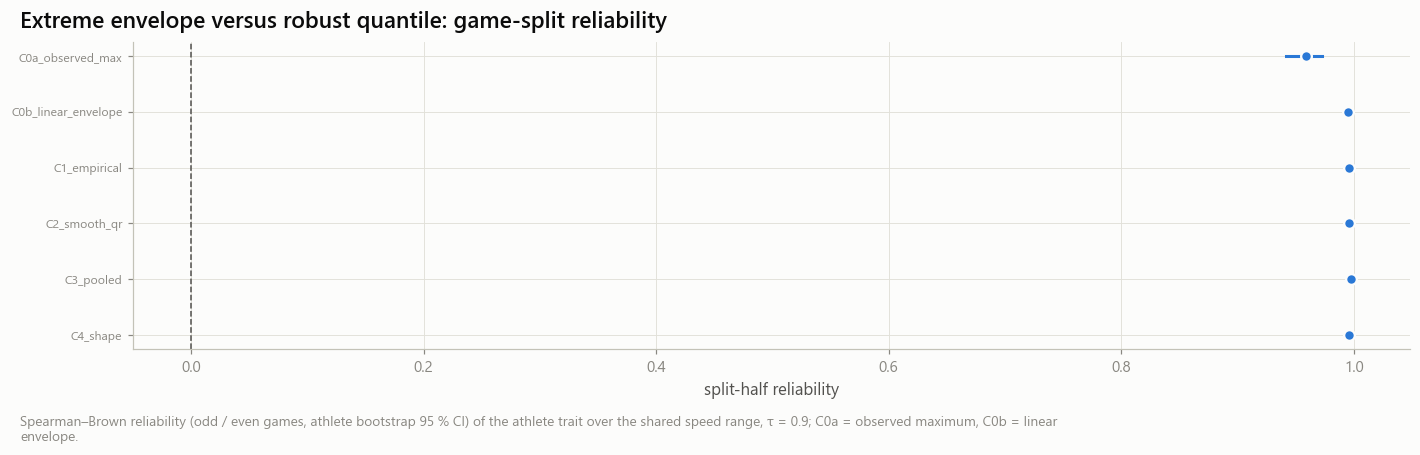

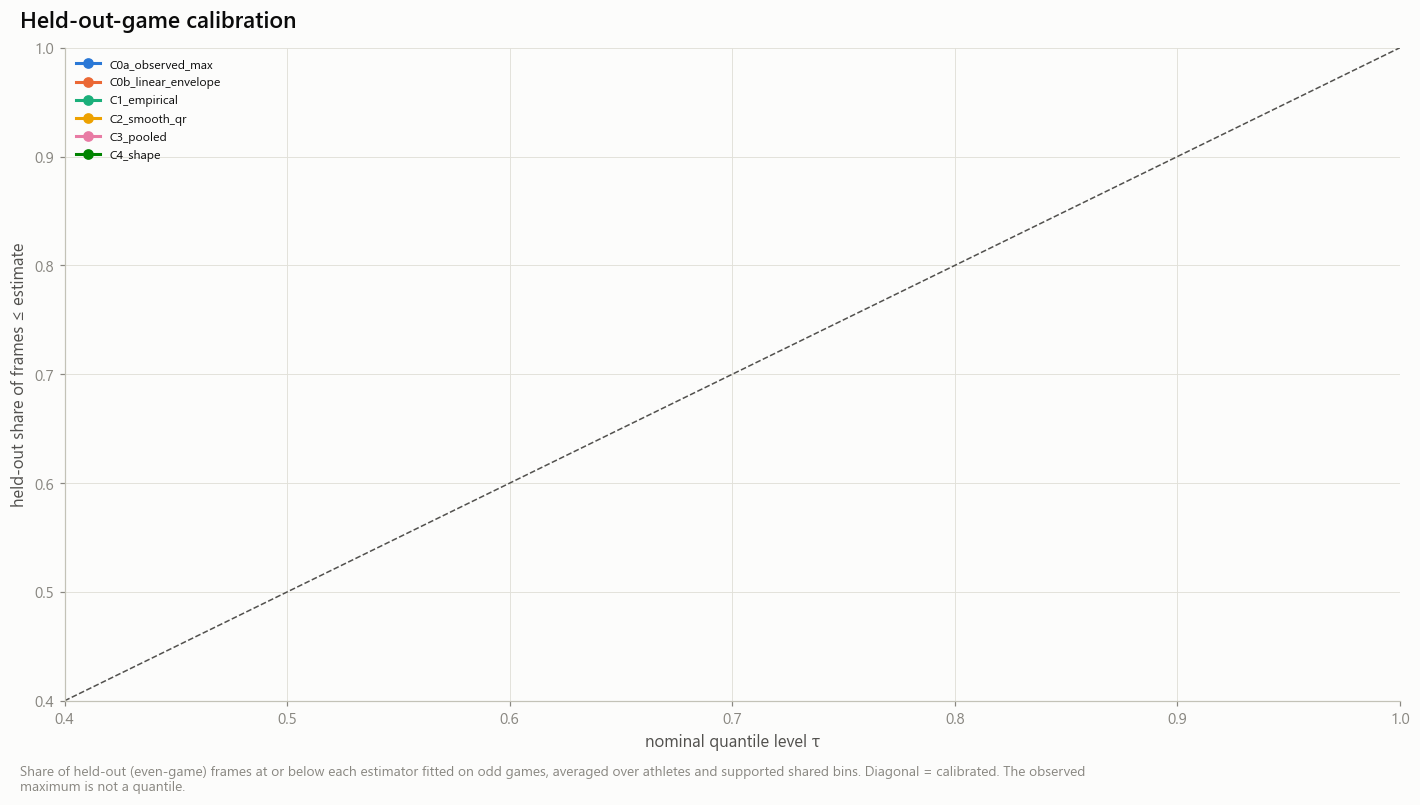

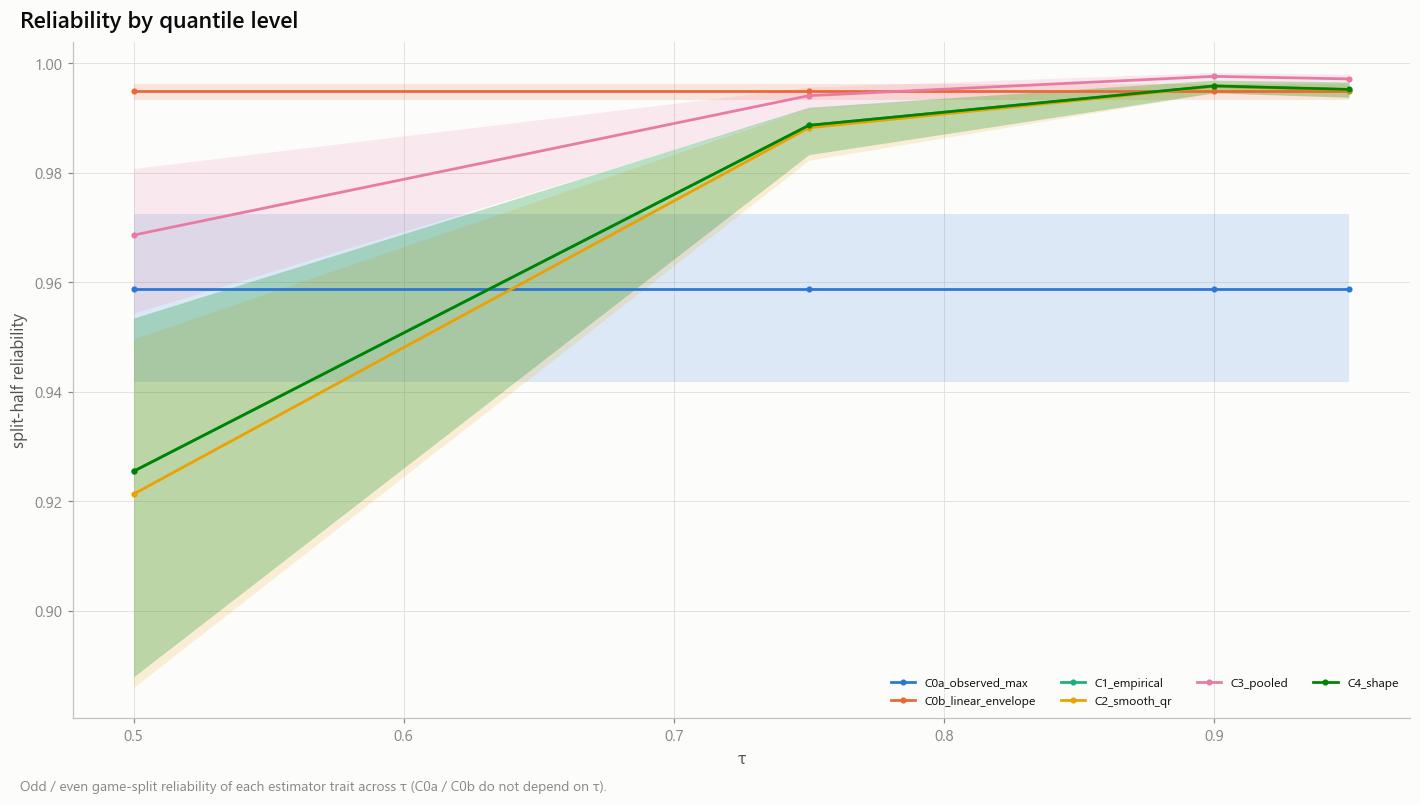

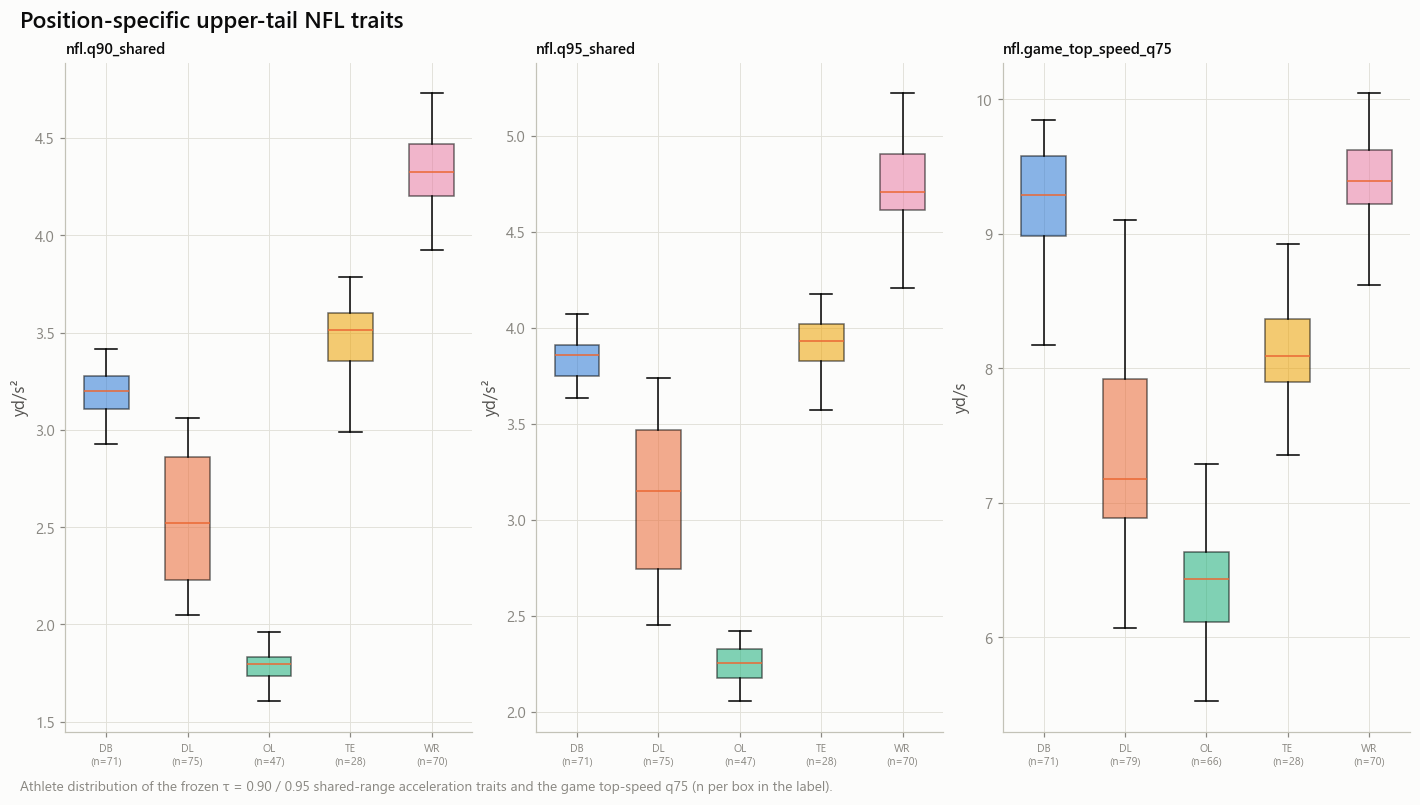

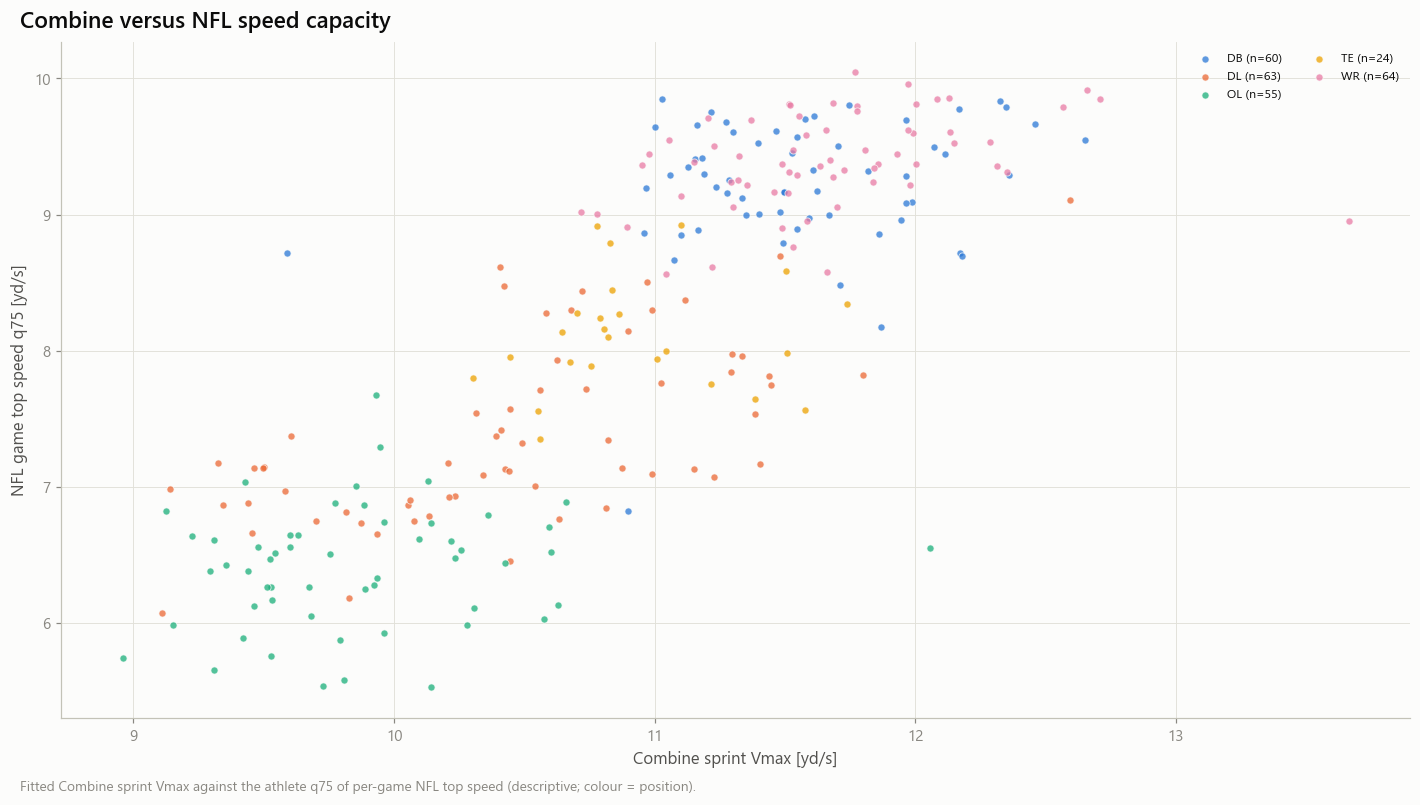

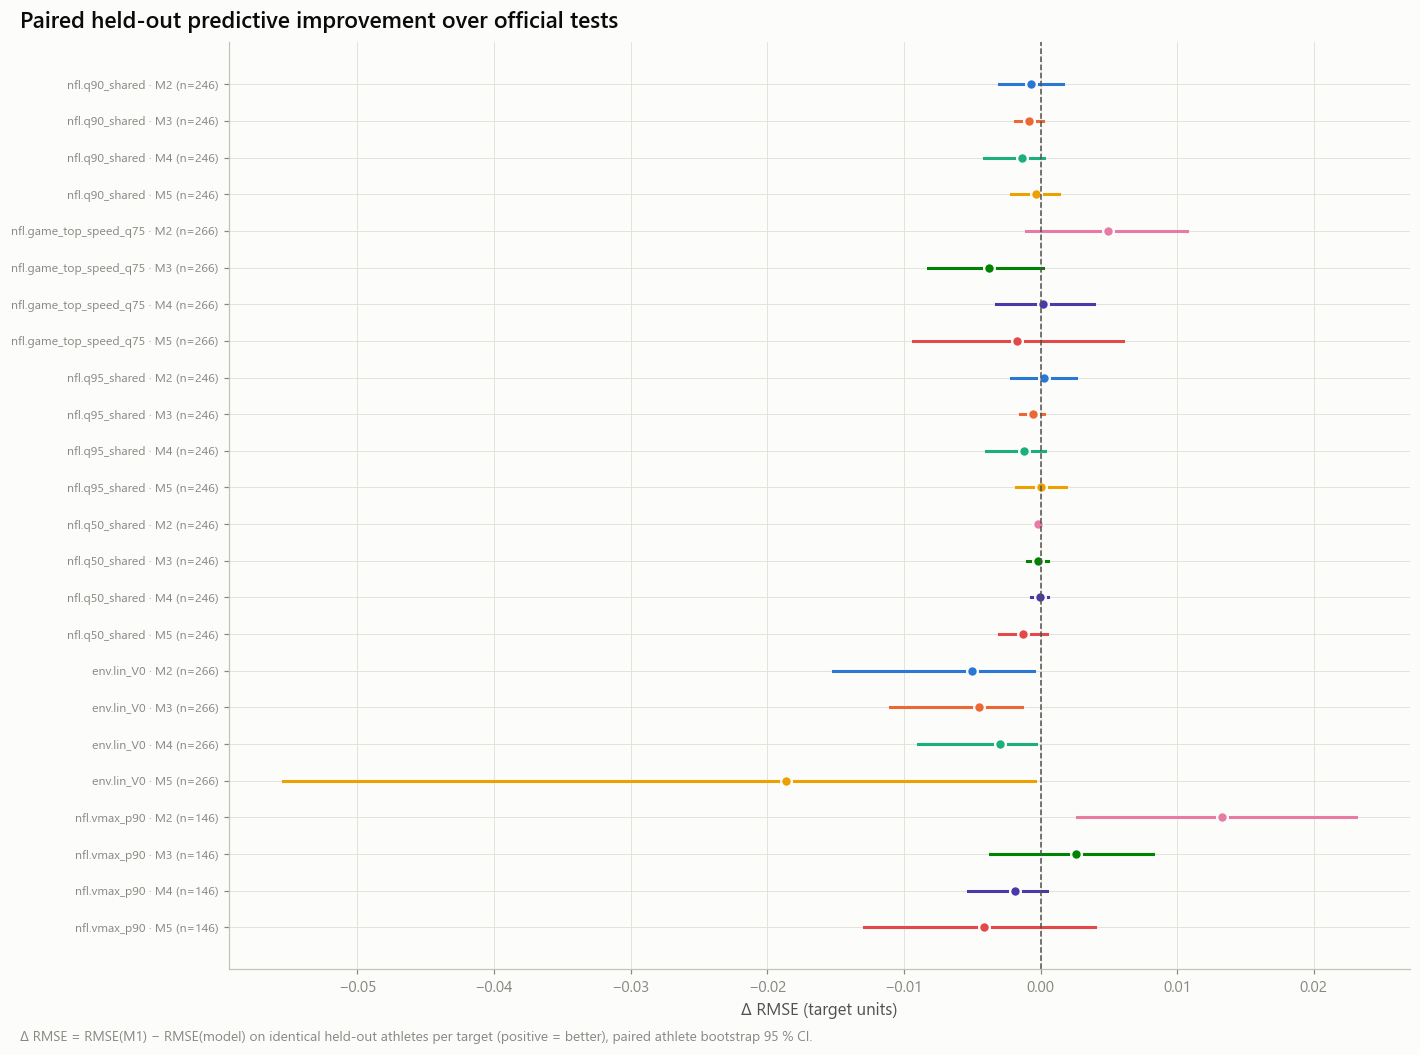

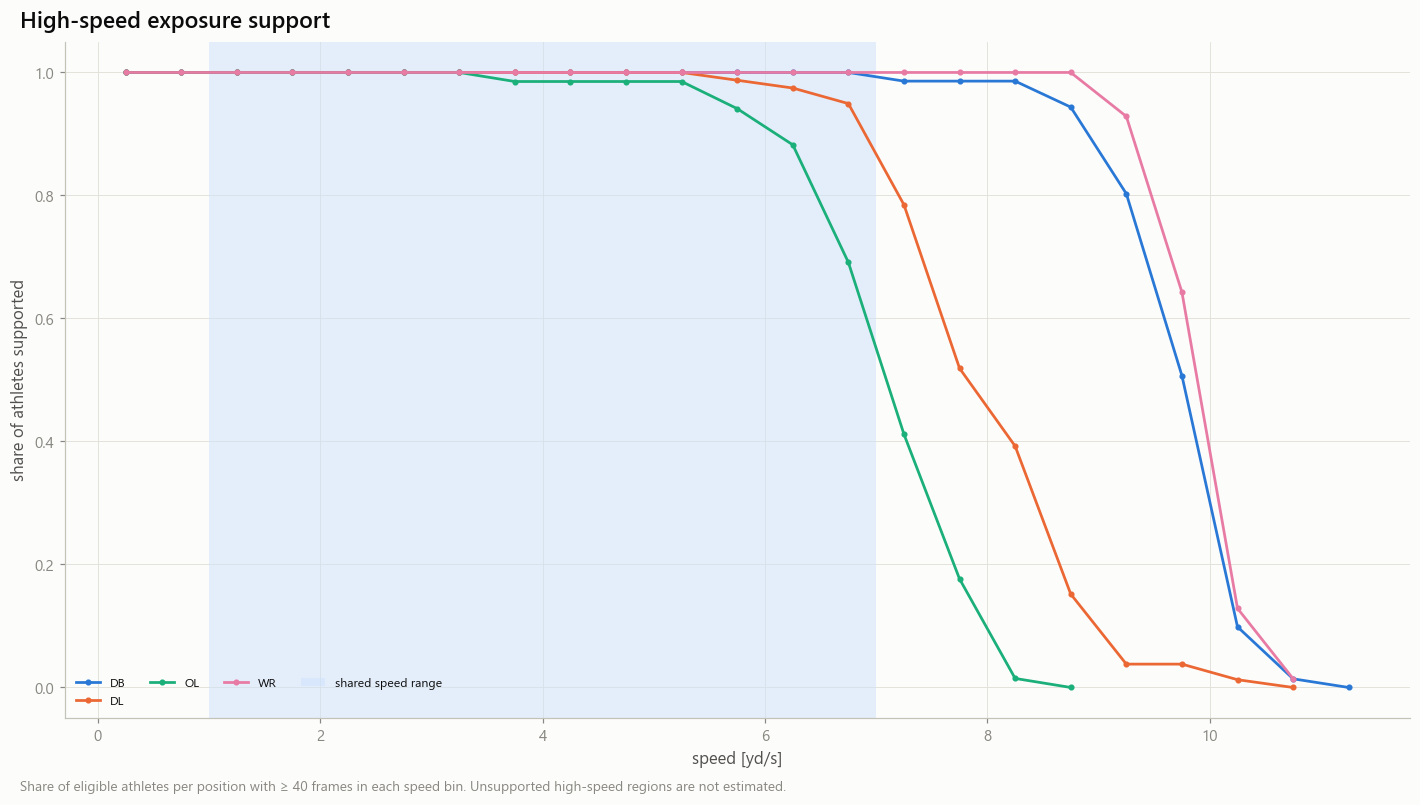

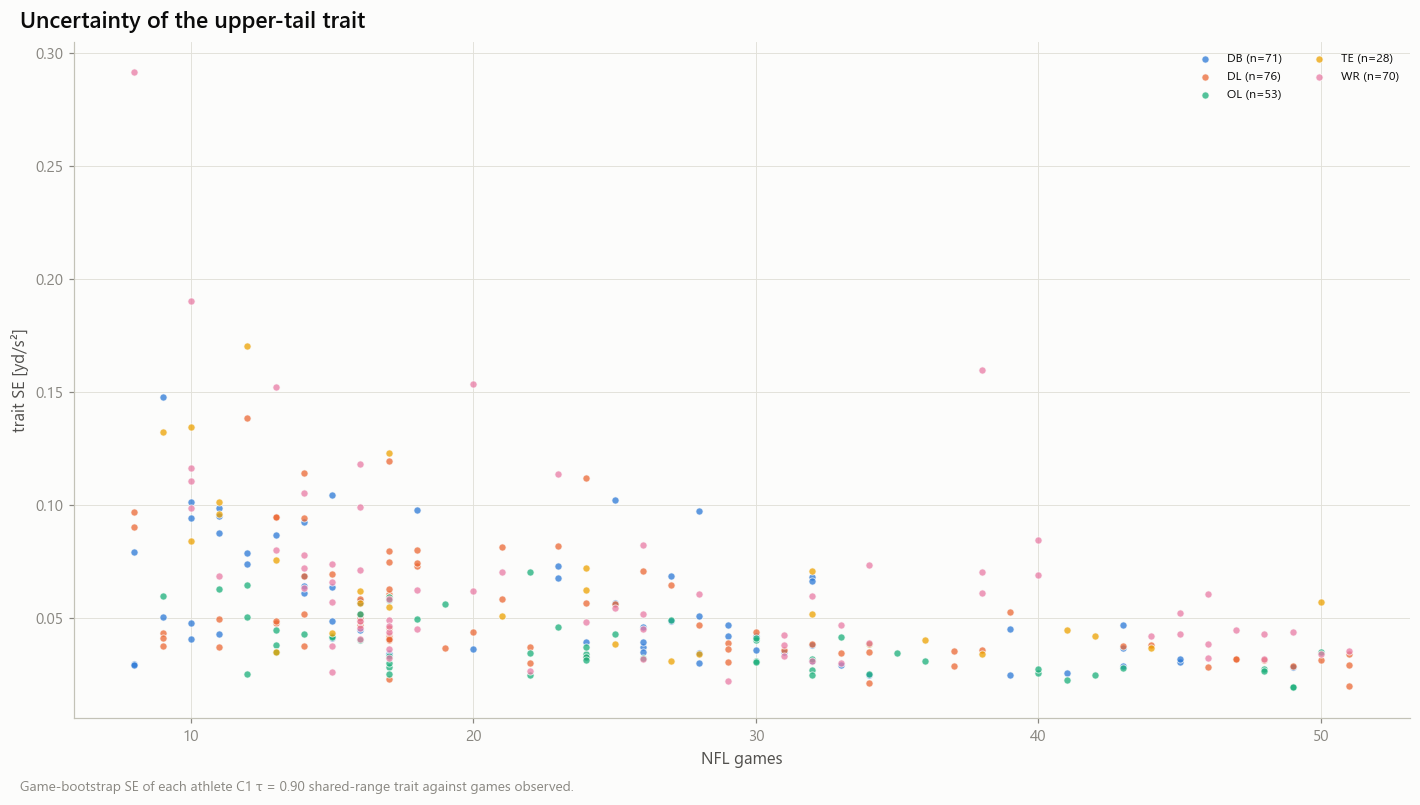

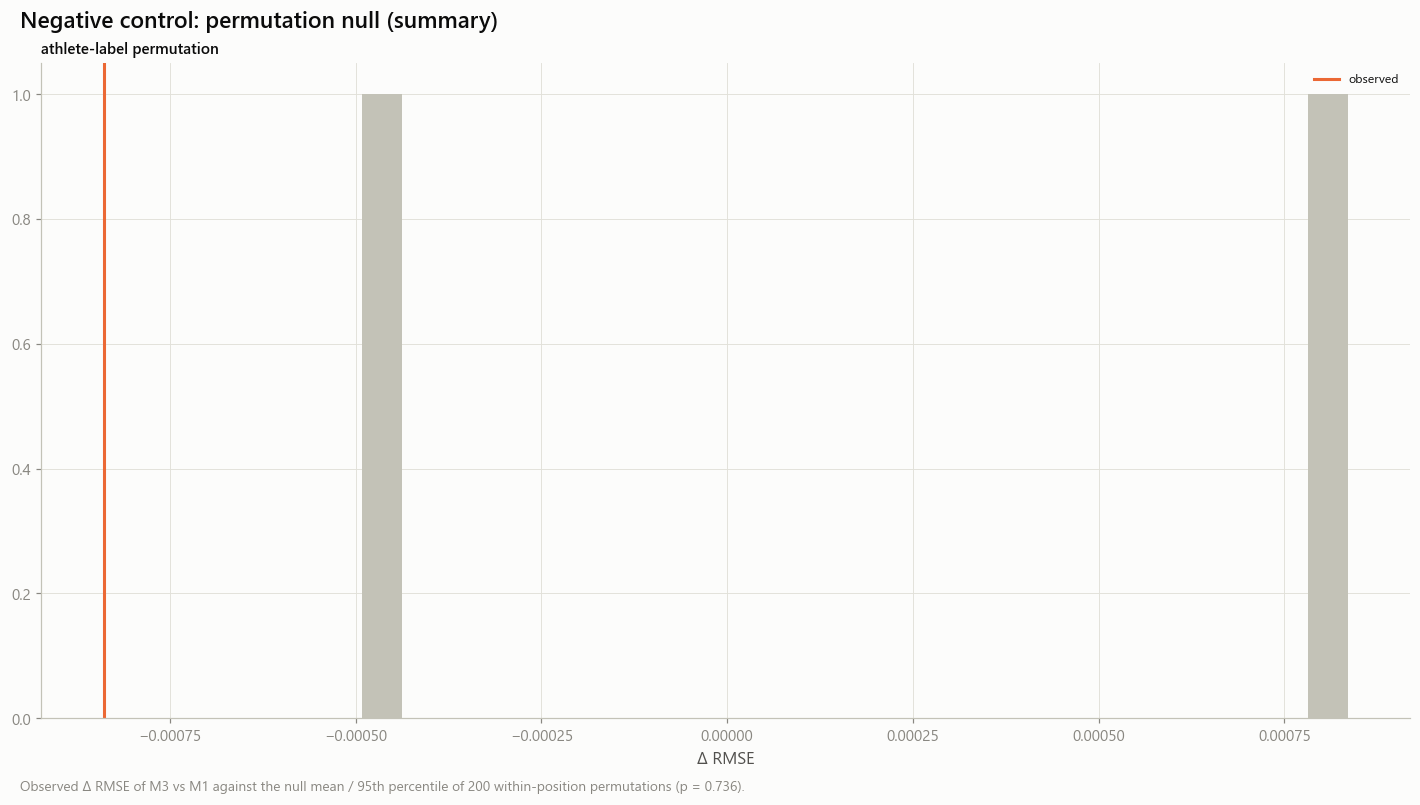

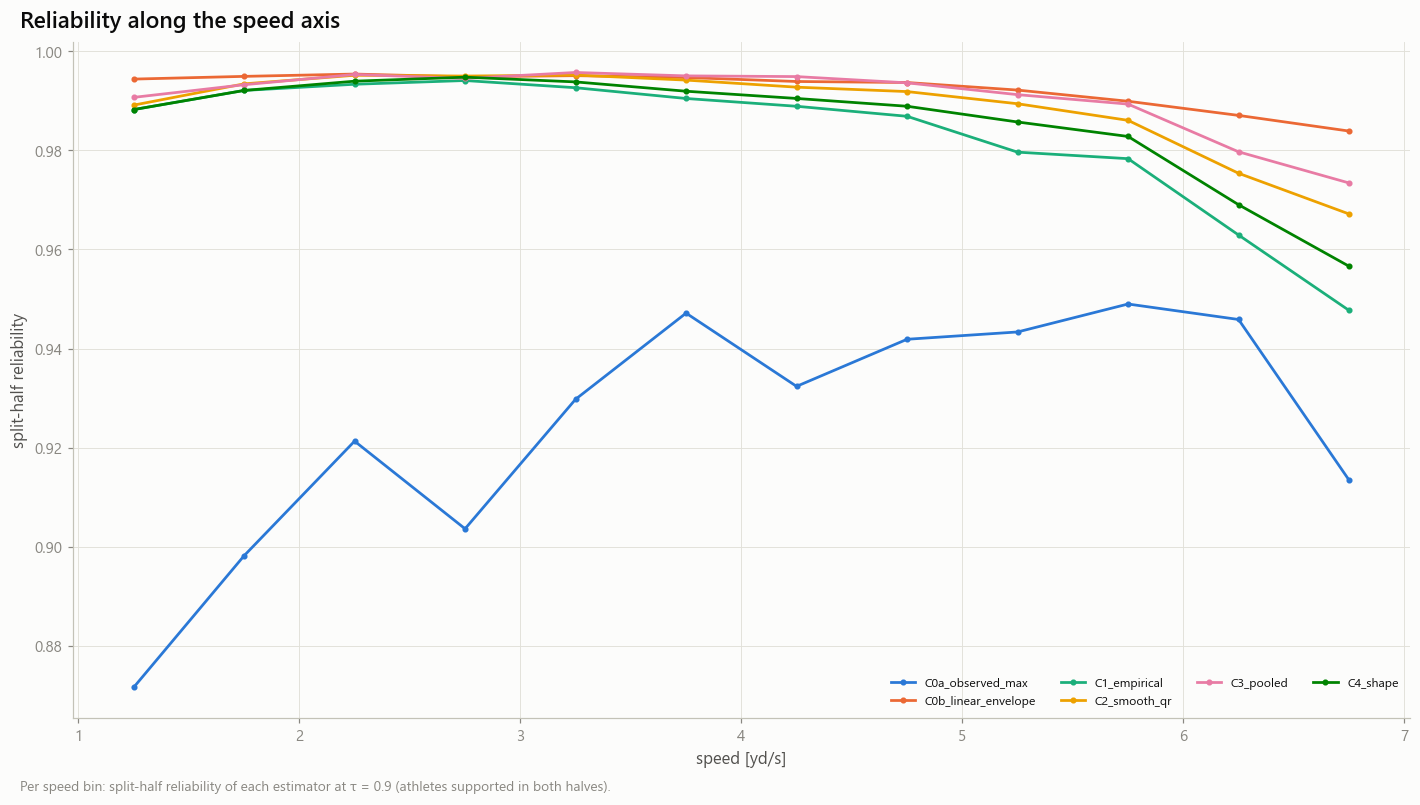

In [16]:
r9 = rel.filter((pl.col('split') == 'odd_even:0') & (pl.col('tau') == C.primary_tau)).sort('estimator')
store.show(fg.fig_forest(r9, 'estimator', 'reliability', 'rel_lo', 'rel_hi', 'Extreme envelope versus robust quantile: game-split reliability',
                         f'Spearman–Brown reliability (odd / even games, athlete bootstrap 95 % CI) of the athlete trait over the shared speed range, τ = {C.primary_tau}; C0a = observed maximum, C0b = linear envelope.',
                         'split-half reliability', ref=0.0), 'AM12_C_03_envelope_vs_quantile_reliability', {'reliability': r9}, publication=True, source='m12c_reliability')
store.show(fg.fig_calibration(fs.filter(pl.col('estimator').is_in(list(dc.ESTIMATORS))), 'Held-out-game calibration',
                              'Share of held-out (even-game) frames at or below each estimator fitted on odd games, averaged over athletes and supported shared bins. Diagonal = calibrated. The observed maximum is not a quantile.'),
           'AM12_C_04_heldout_calibration', {'forecast': fs}, publication=True, source='m12c_forecast_summary')
rq = rel.filter(pl.col('split') == 'odd_even:0').select('tau', 'estimator', 'reliability', 'rel_lo', 'rel_hi')
store.show(fg.fig_lines(rq, 'tau', 'reliability', 'estimator', 'Reliability by quantile level', 'Odd / even game-split reliability of each estimator trait across τ (C0a / C0b do not depend on τ).', 'τ', 'split-half reliability', 'rel_lo', 'rel_hi'),
           'AM12_C_05_reliability_by_quantile', {'reliability': rq}, publication=True, source='m12c_reliability')
lt = tg.unpivot(index=['nfl_id', 'position_group'], on=['nfl.q90_shared', 'nfl.q95_shared', 'nfl.game_top_speed_q75'], variable_name='feature', value_name='value')
store.show(fg.fig_distributions(lt, 'feature', 'value', 'position_group', ['nfl.q90_shared', 'nfl.q95_shared', 'nfl.game_top_speed_q75'], 'Position-specific upper-tail NFL traits',
                                'Athlete distribution of the frozen τ = 0.90 / 0.95 shared-range acceleration traits and the game top-speed q75 (n per box in the label).',
                                {'nfl.q90_shared': 'yd/s²', 'nfl.q95_shared': 'yd/s²', 'nfl.game_top_speed_q75': 'yd/s'}), 'AM12_C_06_position_upper_tail', {'targets': lt}, source='m12c_targets')
store.show(fg.fig_scatter(data.filter(pl.col('forty.sprint_vmax').is_not_null() & pl.col('nfl.game_top_speed_q75').is_not_null()), 'forty.sprint_vmax', 'nfl.game_top_speed_q75',
                          'Combine versus NFL speed capacity', 'Fitted Combine sprint Vmax against the athlete q75 of per-game NFL top speed (descriptive; colour = position).', 'Combine sprint Vmax [yd/s]', 'NFL game top speed q75 [yd/s]'),
           'AM12_C_07_speed_correspondence', {}, publication=True, source='m12c_targets + m11_athlete_features')
tf = tr_rows.filter(pl.col('reference') == 'M1').with_columns((pl.col('target') + ' · ' + pl.col('model') + ' (n=' + pl.col('n_athletes').cast(pl.String) + ')').alias('label'))
store.show(fg.fig_forest(tf, 'label', 'delta_rmse', 'delta_lo', 'delta_hi', 'Paired held-out predictive improvement over official tests',
                         'Δ RMSE = RMSE(M1) − RMSE(model) on identical held-out athletes per target (positive = better), paired athlete bootstrap 95 % CI.', 'Δ RMSE (target units)', color_by='model'),
           'AM12_C_08_heldout_transfer', {'transfer': tf}, publication=True, source='m12c_transfer')
nsup = D.m12('m12_nfl_bin_support').join(pl.DataFrame({'nfl_id': list(POS), 'position_group': list(POS.values())}), on='nfl_id', how='left')
hs = (nsup.filter(pl.col('nfl_id').is_in(list(cubes))).with_columns((pl.col('n_frames') >= C.min_frames_bin_nfl).alias('ok')).group_by('position_group', 'speed_bin')
      .agg(pl.col('ok').sum().alias('n_ok')).join(nsup.filter(pl.col('nfl_id').is_in(list(cubes))).group_by('position_group').agg(pl.col('nfl_id').n_unique().alias('n')), on='position_group')
      .with_columns((pl.col('n_ok') / pl.col('n')).alias('share'), (pl.col('speed_bin') * C.speed_step + C.speed_step / 2).alias('speed')).filter(pl.col('n') >= C.min_athletes))
store.show(fg.fig_lines(hs, 'speed', 'share', 'position_group', 'High-speed exposure support', f'Share of eligible athletes per position with ≥ {C.min_frames_bin_nfl} frames in each speed bin. Unsupported high-speed regions are not estimated.',
                        'speed [yd/s]', 'share of athletes supported', shade=SHARED), 'AM12_C_09_high_speed_support', {'support': hs}, source='m12_nfl_bin_support')
if unc.height:
    store.show(fg.fig_scatter(unc, 'n_games', 'trait_se', 'Uncertainty of the upper-tail trait', 'Game-bootstrap SE of each athlete C1 τ = 0.90 shared-range trait against games observed.', 'NFL games', 'trait SE [yd/s²]'),
               'AM12_C_10_trait_uncertainty', {'uncertainty': unc}, source='m12c_trait_uncertainty')
if perm:
    store.show(fg.fig_null_vs_observed({'athlete-label permutation': np.array([perm['null_mean'], perm['null_q95']])}, {'athlete-label permutation': perm['observed']},
                                       'Negative control: permutation null (summary)', f"Observed Δ RMSE of M3 vs M1 against the null mean / 95th percentile of {perm['n_perm']} within-position permutations (p = {perm['p_value']:.3f}).", 'Δ RMSE'),
               'AM12_C_11_negative_control', {}, source='m12c_permutation')
br = binrel.filter((pl.col('split') == 'odd_even:0') & (pl.col('tau') == C.primary_tau)).with_columns((pl.col('speed_bin') * C.speed_step + C.speed_step / 2).alias('speed'))
store.show(fg.fig_lines(br, 'speed', 'reliability', 'estimator', 'Reliability along the speed axis', f'Per speed bin: split-half reliability of each estimator at τ = {C.primary_tau} (athletes supported in both halves).', 'speed [yd/s]', 'split-half reliability'),
           'AM12_C_12_bin_reliability', {'bin_reliability': br}, source='m12c_bin_reliability')

## Part 10–12 · Conclusions, comparisons for 12G, persisted artifacts, next questions

## 12C — conclusion (inconclusive; run mode full; generated 2026-10-15T00:42:13Z)

### Research question
Q3 — Are stable NFL movement distributions better targets than maxima / linear envelopes, and do Combine speed features predict them beyond official tests?

### Declared primary hypothesis
Upper conditional acceleration quantiles (τ = 0.90) over the shared speed range are more game-split reliable than the observed-maximum envelope; fitted sprint Vmax (M3) lowers held-out RMSE of that target vs M1.

### Primary outcome / comparison
nfl.q90_shared (estimator frozen by the declared reliability rule before any Combine value is joined); secondary nfl.game_top_speed_q75 — M3 vs M1 on the primary target; M2 vs M1 on the secondary target (Holm over the two) (evaluation target: `cross_domain_physical_transfer`)

### Sample
316 NFL athletes (≥ 8 games); transfer cohort 267 linked athletes; shared range 1.0–7.0 yd/s.

### Main evidence (from persisted tables)
- frozen estimator C3_pooled (τ = 0.9)
- C1_empirical vs C0a_observed_max: reliability 0.996 vs 0.959, Δ 0.037 [0.023, 0.054] (n=241) — supported
- C1_empirical vs C0b_linear_envelope: reliability 0.996 vs 0.995, Δ 0.001 [-0.000, 0.002] (n=241) — inconclusive
- C2_smooth_qr vs C0a_observed_max: reliability 0.996 vs 0.959, Δ 0.037 [0.023, 0.054] (n=241) — supported
- C2_smooth_qr vs C0b_linear_envelope: reliability 0.996 vs 0.995, Δ 0.001 [-0.000, 0.002] (n=241) — inconclusive
- C3_pooled vs C0a_observed_max: reliability 0.998 vs 0.959, Δ 0.039 [0.025, 0.056] (n=241) — supported
- C3_pooled vs C0b_linear_envelope: reliability 0.998 vs 0.995, Δ 0.003 [0.002, 0.004] (n=241) — supported
- C4_shape vs C0a_observed_max: reliability 0.996 vs 0.959, Δ 0.037 [0.023, 0.054] (n=241) — supported
- C4_shape vs C0b_linear_envelope: reliability 0.996 vs 0.995, Δ 0.001 [-0.000, 0.002] (n=241) — inconclusive
- M3 vs M1 → nfl.q90_shared: Δ RMSE -0.0008 [-0.0018, 0.0002] (n=246, Holm p 0.949) — inconclusive
- M2 vs M1 → nfl.game_top_speed_q75: Δ RMSE 0.0050 [-0.0010, 0.0107] (n=266, Holm p 0.098) — inconclusive
- replication forty.sprint_vmax: 9 variants, share with Δ CI > 0 = 0.00, share Δ > 0 = 0.11
- replication forty.v_max_obs: 8 variants, share with Δ CI > 0 = 0.38, share Δ > 0 = 1.00

### Alternative explanations
- Role and play design decide when athletes accelerate: an upper quantile mixes capacity with opportunity.
- Position and body size are shared causes of Combine and NFL speed; M1 holds them but not every within-position difference.
- The 11B high-speed gains were selected among many comparisons; a replication share near the noise level is expected under no effect.

### Practical interpretation
Defines whether a reproducible, context-aware NFL movement target exists that can replace unstable maxima, and whether Combine speed predicts it beyond the stopwatch.

### Limitations
- One cohort; held-out gains are exploratory until an independent draft class confirms them.
- No play context (down, alignment, route) in the histograms.
- C5 (distributional forest) not implemented.
- Shared range excludes unsupported high-speed bins by design.

### Next research questions
- Re-run the frozen target on a later draft class (independent confirmation).
- Condition quantiles on play context where tracking supplies it.


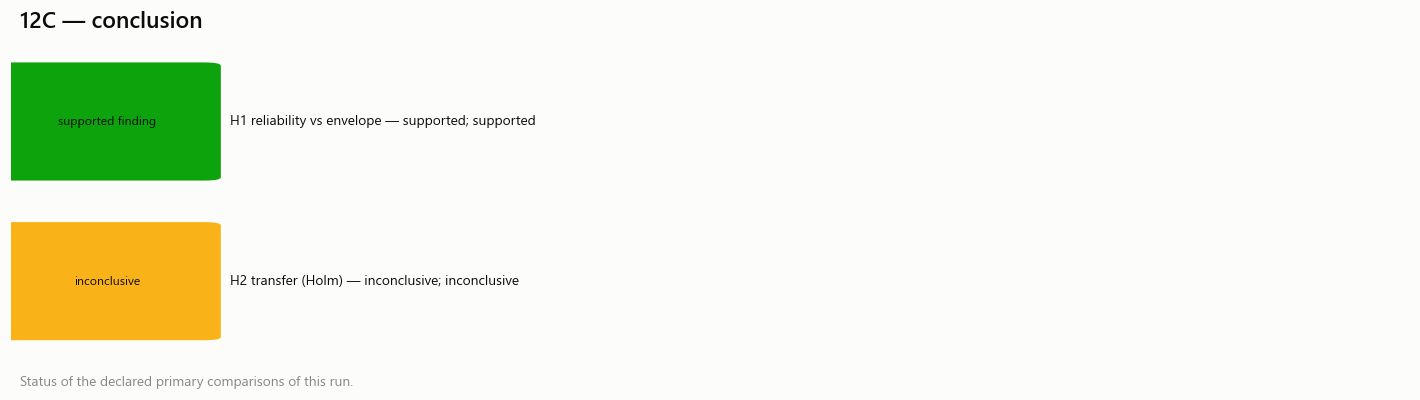

Send back: checks, λ tuning, the reliability tables + difference table, forecast summary, the freeze line, transfer + permutation + by-position tables, replication tables, the conclusion.
Next: 12b_measurement_error_and_latent_traits.ipynb


In [17]:
rm = controls.run_mode
comps = [sy.comparison_row('12C', f"reliability {r['estimator']} vs {r['reference']} (τ={r['tau']})", 'reliability difference', r['diff'], r['lo'], r['hi'], r['n_athletes'],
                           m12c.RELIABILITY, 'm12c_reliability_difference', rm, experiment=3, primary=True) for r in rdiff.iter_rows(named=True)]
comps += [sy.comparison_row('12C', f"held-out pinball {r['estimator']} vs C1 (τ={r['tau']})", 'pinball gain', r['gain_vs_ref'], r['gain_lo'], r['gain_hi'], r['n_athletes'],
                            m12c.RELIABILITY, 'm12c_forecast_summary', rm, experiment=3) for r in fs.filter(pl.col('estimator') != 'C1_empirical').iter_rows(named=True)]
comps += [sy.comparison_row('12C', f"transfer {r['model']} vs {r['reference']} → {r['target']}", 'Δ RMSE', r['delta_rmse'], r['delta_lo'], r['delta_hi'], r['n_athletes'],
                            m12c.PHYSICAL_TRANSFER, 'm12c_transfer', rm, primary=bool(r['primary'])) for r in tr_rows.iter_rows(named=True)]
comps += [sy.comparison_row('12C', f"replication {r['feature']} → {r['target']} [{r['variant']}]", 'Δ RMSE', r.get('delta_rmse'), r.get('delta_lo'), r.get('delta_hi'), r.get('n_athletes'),
                            m12c.PHYSICAL_TRANSFER, 'm12c_replication', rm) for r in rep_tab.filter(pl.col('status') == 'computed').iter_rows(named=True)] if rep_tab.height else []
COMP = sy.comparison_frame(comps)
W(COMP, 'm12c_comparisons')
ev_rows = []
for r in rel.filter((pl.col('split') == 'odd_even:0') & (pl.col('tau') == C.primary_tau)).iter_rows(named=True):
    ev_rows.append(ae.evidence_row(f"nfl.{r['estimator']}.q90_shared", '12C', experiment='3', physical_interpretation='upper conditional acceleration over the shared speed range',
                                   input_data='m11_envelope_hist', output='athlete trait [yd/s²]', n_athletes=r['n_athletes'], reliability=r['reliability'], reliability_lo=r['rel_lo'],
                                   reliability_hi=r['rel_hi'], compute_cost='minutes', evaluation_target=m12c.RELIABILITY, run_mode=rm, config_hash=C.hash(),
                                   limitations='observed under game opportunity; no play context in the histograms'))
for r in tr_rows.filter(pl.col('reference') == 'M1').iter_rows(named=True):
    ev_rows.append(ae.evidence_row(f"12C.{r['model']}→{r['target']}", '12C', physical_interpretation=MODELS[r['model']].note, input_data='Combine + officials', output=r['target'],
                                   n_athletes=r['n_athletes'], delta_rmse=r['delta_rmse'], delta_lo=r['delta_lo'], delta_hi=r['delta_hi'], compute_cost='seconds',
                                   evaluation_target=m12c.PHYSICAL_TRANSFER, training_regime=m12c.INDUCTIVE, run_mode=rm, config_hash=C.hash()))
EVID = ae.evidence_frame(ev_rows)
W(EVID, 'm12c_evidence')
h1 = [r['verdict'] for r in rdiff.filter(pl.col('estimator') == FREEZE['estimator']).iter_rows(named=True)]
h2 = [r['verdict'] for r in tr_rows.filter(pl.col('primary')).iter_rows(named=True)]
status = rp.status_from([*h1, *h2])
facts = {'status': status, 'run_mode': rm,
         'sample': f'{len(cubes)} NFL athletes (≥ {C.min_games_athlete} games); transfer cohort {data.height} linked athletes; shared range {SHARED[0]}–{SHARED[1]} yd/s.',
         'evidence': [f"frozen estimator {FREEZE['estimator']} (τ = {FREEZE['tau']})"]
                     + [f"{r['estimator']} vs {r['reference']}: reliability {rp.fmt(r['rel_a'])} vs {rp.fmt(r['rel_b'])}, Δ {rp.ci(r['diff'], r['lo'], r['hi'])} (n={r['n_athletes']}) — {r['verdict']}" for r in rdiff.iter_rows(named=True)]
                     + [f"{r['model']} vs M1 → {r['target']}: Δ RMSE {rp.ci(r['delta_rmse'], r['delta_lo'], r['delta_hi'], 4)} (n={r['n_athletes']}, Holm p {rp.fmt(r['p_holm_primary'])}) — {r['verdict']}" for r in tr_rows.filter(pl.col('primary')).iter_rows(named=True)]
                     + ([f"replication {r['feature']}: {r['n_variants']} variants, share with Δ CI > 0 = {rp.fmt(r['share_ci_above_0'], 2)}, share Δ > 0 = {rp.fmt(r['share_positive'], 2)}" for r in rep_sum.iter_rows(named=True)] if rep_sum.height else []),
         'alternatives': ['Role and play design decide when athletes accelerate: an upper quantile mixes capacity with opportunity.',
                          'Position and body size are shared causes of Combine and NFL speed; M1 holds them but not every within-position difference.',
                          'The 11B high-speed gains were selected among many comparisons; a replication share near the noise level is expected under no effect.'],
         'relevance': 'Defines whether a reproducible, context-aware NFL movement target exists that can replace unstable maxima, and whether Combine speed predicts it beyond the stopwatch.',
         'limitations': ['One cohort; held-out gains are exploratory until an independent draft class confirms them.', 'No play context (down, alignment, route) in the histograms.',
                         'C5 (distributional forest) not implemented.', 'Shared range excludes unsupported high-speed bins by design.'],
         'next': ['Re-run the frozen target on a later draft class (independent confirmation).', 'Condition quantiles on play context where tracking supplies it.']}
md = rp.conclusion_markdown('12C', facts)
display(Markdown(md))
rp.write_conclusion(store, '12C', md)
block = md + chr(10) + '### Reliability (odd / even games, τ = primary)' + chr(10) + chr(10) + rp.md_table(r9, ['estimator', 'n_athletes', 'reliability', 'rel_lo', 'rel_hi', 'shape_agreement']) \
        + chr(10) + '### Transfer (identical athletes per target)' + chr(10) + chr(10) + rp.md_table(tr_rows, ['target', 'model', 'reference', 'n_athletes', 'delta_rmse', 'delta_lo', 'delta_hi', 'p_holm_primary', 'verdict'])
rp.update_doc(store, 'DISTRIBUTIONAL_CAPACITY.md', block)
rp.run_manifest(store, '12C', PROV, ['m12c_reliability', 'm12c_forecast_summary', 'm12c_targets', 'm12c_transfer', 'm12c_replication', 'm12c_comparisons', 'm12c_evidence'], status,
                {'freeze_hash': FREEZE['freeze_hash'], 'estimator': FREEZE['estimator']})
store.show(fg.fig_conclusion(pl.DataFrame([{'item': 'H1 reliability vs envelope', 'evidence': '; '.join(h1) or '—', 'status': rp.status_from(h1)},
                                           {'item': 'H2 transfer (Holm)', 'evidence': '; '.join(h2) or '—', 'status': rp.status_from(h2)}]),
                             '12C — conclusion', 'Status of the declared primary comparisons of this run.'), 'AM12_C_13_conclusion', {}, publication=True, source='m12c_comparisons')
print('Send back: checks, λ tuning, the reliability tables + difference table, forecast summary, the freeze line, transfer + permutation + by-position tables, replication tables, the conclusion.')
print('Next: 12b_measurement_error_and_latent_traits.ipynb')